/tmp/ipykernel_1421/819791775.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
/tmp/ipykernel_1421/819791775.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0, 0], data=df, x='Churn', palette=['#2b5c8f', '#d9534f'])


--- DATASET SUMMARY ---
Total Customers Analyzed: 7043
Overall Churn Rate: 26.54%



/tmp/ipykernel_1421/819791775.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1, 1], data=df, x='Churn', y='tenure', palette=['#2b5c8f', '#d9534f'])


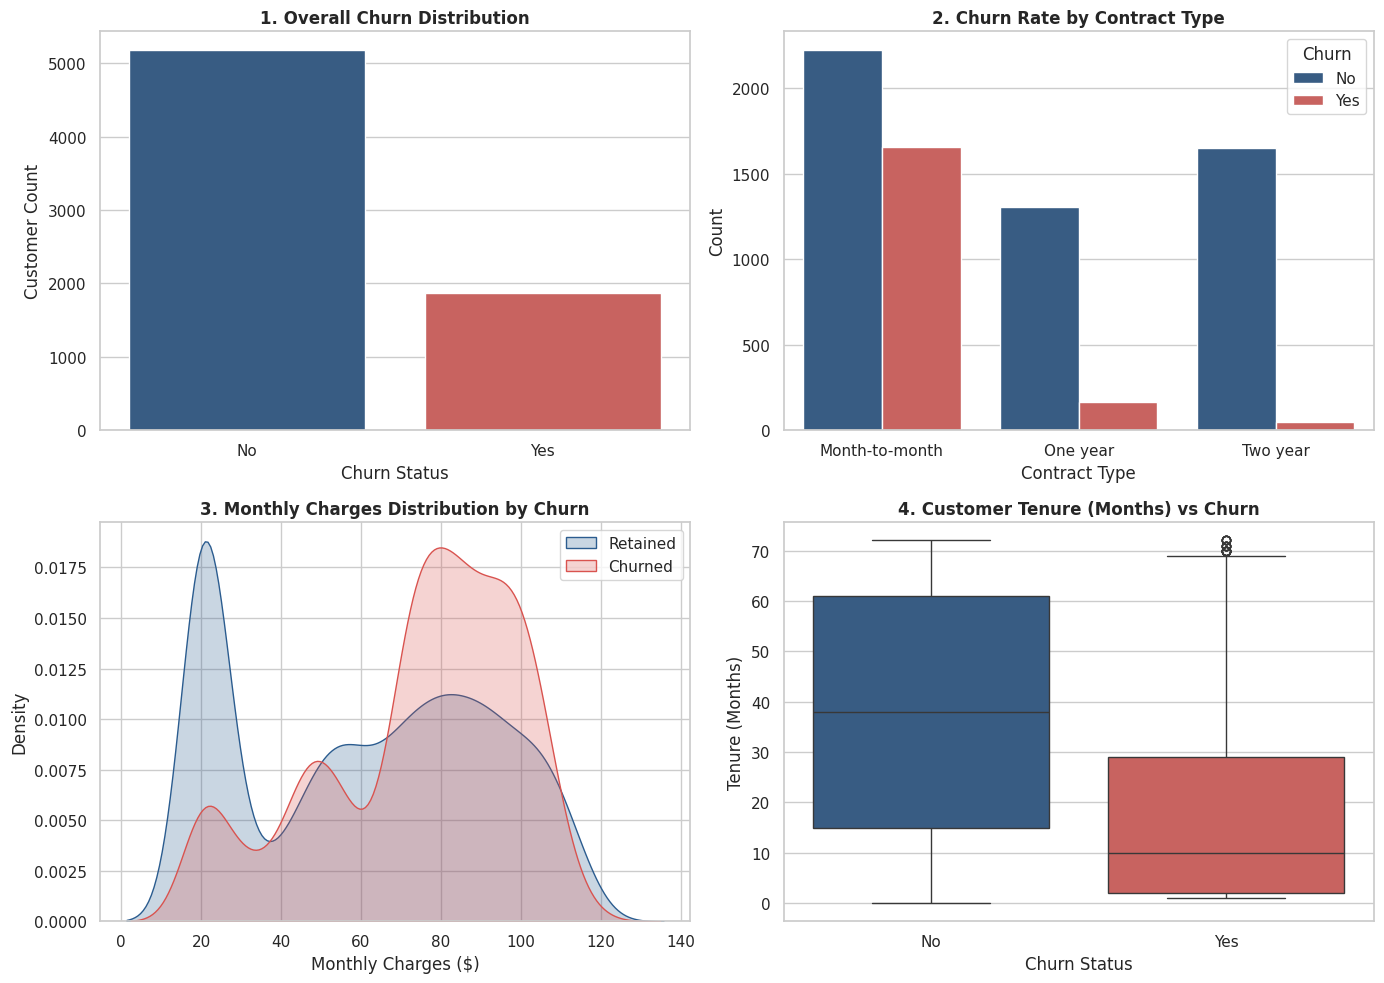

--- CHURN RATE BY CONTRACT ---
Contract
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: Yes, dtype: object


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Clean, professional chart theme
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Load Standard Telco Churn Dataset directly via URL
dataset_url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(dataset_url)

# 2. Data Cleaning & Preprocessing
# Fix TotalCharges whitespace issue
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Drop CustomerID as it's non-informative
df.drop(columns=['customerID'], inplace=True)

# Display Baseline Metrics
churn_rate = (df['Churn'].value_counts(normalize=True)['Yes']) * 100
print(f"--- DATASET SUMMARY ---")
print(f"Total Customers Analyzed: {len(df)}")
print(f"Overall Churn Rate: {churn_rate:.2f}%\n")

# 3. Visual Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Target Variable Distribution (Churn vs Retained)
sns.countplot(ax=axes[0, 0], data=df, x='Churn', palette=['#2b5c8f', '#d9534f'])
axes[0, 0].set_title("1. Overall Churn Distribution", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Churn Status")
axes[0, 0].set_ylabel("Customer Count")

# Chart 2: Churn by Contract Type (Key Retention Driver)
sns.countplot(ax=axes[0, 1], data=df, x='Contract', hue='Churn', palette=['#2b5c8f', '#d9534f'])
axes[0, 1].set_title("2. Churn Rate by Contract Type", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Contract Type")
axes[0, 1].set_ylabel("Count")

# Chart 3: Monthly Charges vs Churn (KDE Distribution)
sns.kdeplot(ax=axes[1, 0], data=df[df['Churn'] == 'No']['MonthlyCharges'], label='Retained', fill=True, color='#2b5c8f')
sns.kdeplot(ax=axes[1, 0], data=df[df['Churn'] == 'Yes']['MonthlyCharges'], label='Churned', fill=True, color='#d9534f')
axes[1, 0].set_title("3. Monthly Charges Distribution by Churn", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Monthly Charges ($)")
axes[1, 0].legend()

# Chart 4: Tenure Distribution (How long customers stay before leaving)
sns.boxplot(ax=axes[1, 1], data=df, x='Churn', y='tenure', palette=['#2b5c8f', '#d9534f'])
axes[1, 1].set_title("4. Customer Tenure (Months) vs Churn", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Churn Status")
axes[1, 1].set_ylabel("Tenure (Months)")

plt.tight_layout()
plt.savefig("customer_churn_eda_dashboard.png", dpi=300)
plt.show()

# 4. Statistical Retention Insights
cohort_summary = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
print("--- CHURN RATE BY CONTRACT ---")
print(cohort_summary.apply(lambda x: f"{x:.2f}%"))